# RandomForest_Final: the MloHub demand-forecasting ML engine

**ICS 3202 Artificial Intelligence · Project Deliverable 3 (final ML module for code review)**
**Group 18:** 189946 Jason Kuria Wainaina · 189983 Kioko John Musyimi · 176833 Michelle Wachanga Wangui
**Project:** MloHub, an affordable multi-tenant food ordering and business-intelligence platform for small food vendors

**What the engine does, in one sentence:** for a chosen dish and day, it estimates how many portions customers will buy, so the vendor can prepare enough food without waste.

| Notebook | What it contains |
|---|---|
| [`FoodDemandForecasting_Exploration.ipynb`](FoodDemandForecasting_Exploration.ipynb) | Deliverable 1: dataset discovery and exploration |
| [`RandomForest_Base.ipynb`](RandomForest_Base.ipynb) | Deliverable 2: the **base model**: cleaning, EDA, tuning, comparison with other algorithms |
| **`RandomForest_Final.ipynb`** (this one) | Deliverable 3: the **final engine** exactly as the app runs it, from raw data to explained predictions |

The notebook follows the six **CRISP-DM** stages (the standard data-mining process):

| Stage | Section |
|---|---|
| 1. Business understanding | §1 |
| 2. Data understanding | §2 |
| 3. Data preparation | §3 |
| 4. Modelling | §4 |
| 5. Evaluation | §5 |
| 6. Deployment (how the app uses the model, input checks, explanations) | §6 – §8 |

**Honesty note:** MloHub has no paying customers yet. The sales history is **demonstration data** generated in the app for the restaurant *Campus Bites*. The results show how the methods behave on this data, not proven real-world accuracy.

## 1. Business understanding

**The user:** the owner or manager of a small food business on MloHub (our demo restaurant is *Campus Bites*, 21 dishes).

**The question they ask every evening:** *"How many portions of each dish should I prepare for tomorrow?"*
* Prepare too much → food is thrown away (lost money).
* Prepare too little → customers leave unhappy (lost sales).

**The ML task:** **regression**, i.e. predicting a number (portions of one dish on the next day) rather than a category.

**How we judge success:** the **MAE (Mean Absolute Error)**: on average, how many portions the forecast is off by. MAE = 2 means "usually wrong by about 2 portions". Lower is better. A model is only worth using if it beats simple rules a vendor could work out by hand (for example "same as the average of the last 7 days").

### Setup
We fix a **random seed** (2026) so the random parts of the forest come out the same on every run and every group member gets identical results. The data file is read from the repository's `data/` folder, or downloaded from GitHub when the notebook runs in Google Colab.

In [1]:
import hashlib, json, platform, warnings, datetime as dt, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, joblib
from sklearn.ensemble import RandomForestRegressor
from IPython.display import display

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})
pd.set_option("display.width", 140)

SEED = 2026
REPO_RAW = "https://raw.githubusercontent.com/JasonKuria/SemProject_MLEngine/main/data/"
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)

def get_file(name):
    # use the local copy in data/ if it exists, otherwise download it from the GitHub repository
    local = Path("data") / name
    if not local.is_file():
        local.parent.mkdir(exist_ok=True)
        urllib.request.urlretrieve(REPO_RAW + name, local)
    return local

print("Python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)

Python 3.13.5 | pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1


## 2. Data understanding

### 2.1 Load the data and check it is the approved file
Each row is **one dish on one day**: the date, the dish, and the number of portions sold (completed orders only). The file was exported once from the MloHub database for 27 Aug – 25 Oct 2026, and its fingerprint (SHA-256 hash) was recorded. If the fingerprint matches, we know we are training on exactly the same data as the app's model.

In [2]:
path = get_file("campus_bites_daily_sales.csv")
APPROVED_SHA256 = "25b257bb982d5175b3203d1e7bc21af905a253c40de616fa2e521905bd5929a7"
sha = hashlib.sha256(path.read_bytes().replace(b"\r\n", b"\n")).hexdigest()   # ignore Windows line endings
print("File fingerprint matches the approved extraction:", sha == APPROVED_SHA256)

raw = pd.read_csv(path, parse_dates=["date"])
print(f"{len(raw):,} rows x {raw.shape[1]} columns")
display(raw.head())
print(raw.dtypes.to_string())

File fingerprint matches the approved extraction: True
1,260 rows x 4 columns


,date,dish_slug,dish_name,portions
0,2026-08-27,beef-stew,Beef Stew,1
1,2026-08-27,burger-combo,Burger Combo,4
2,2026-08-27,cheeseburger,Cheeseburger,4
3,2026-08-27,chicken-burger,Chicken Burger,3
4,2026-08-27,chicken-pilau,Chicken Pilau,4


date         datetime64[us]
dish_slug               str
dish_name               str
portions              int64


### 2.2 Data-quality checks
Before modelling we confirm the data is complete and sensible. Each check is an `assert`: if one fails, the notebook stops instead of training on bad data.

In [3]:
checks = {
    "no missing values":                       raw.isna().sum().sum() == 0,
    "no duplicated (date, dish) rows":         not raw.duplicated(["date", "dish_slug"]).any(),
    "portions are whole numbers >= 0":         (raw["portions"] >= 0).all() and (raw["portions"] % 1 == 0).all(),
    "every dish appears on every day":         raw.groupby("date")["dish_slug"].nunique().eq(raw["dish_slug"].nunique()).all(),
    "dates are consecutive (no gaps)":         raw["date"].drop_duplicates().sort_values().diff().dropna().eq(pd.Timedelta(days=1)).all(),
    "60 days, 21 dishes, 3,666 portions":      (raw["date"].nunique(), raw["dish_slug"].nunique(), raw["portions"].sum()) == (60, 21, 3666),
}
for name, ok in checks.items():
    print(f"  {'PASS' if ok else 'FAIL'}  {name}")
assert all(checks.values()), "data-quality check failed: stop and investigate"

# The sales matrix: one row per day, one column per dish. Days with no sale of a dish are 0 (already in the file).
Q = raw.pivot(index="date", columns="dish_slug", values="portions").sort_index()
DISHES = list(Q.columns)                                  # alphabetical, fixed order (the model depends on it)
NAMES = raw.drop_duplicates("dish_slug").set_index("dish_slug")["dish_name"].to_dict()
TOTAL = Q.sum(axis=1)                                     # whole-restaurant portions per day
print(f"\nSales matrix: {Q.shape[0]} days x {Q.shape[1]} dishes | {Q.index.min().date()} -> {Q.index.max().date()}")

  PASS  no missing values
  PASS  no duplicated (date, dish) rows
  PASS  portions are whole numbers >= 0
  PASS  every dish appears on every day
  PASS  dates are consecutive (no gaps)
  PASS  60 days, 21 dishes, 3,666 portions

Sales matrix: 60 days x 21 dishes | 2026-08-27 -> 2026-10-25


### 2.3 Exploratory data analysis (EDA)
We ask the data a few questions with charts and numbers. Every observation below is **calculated by code**, so it stays correct if the data changes.

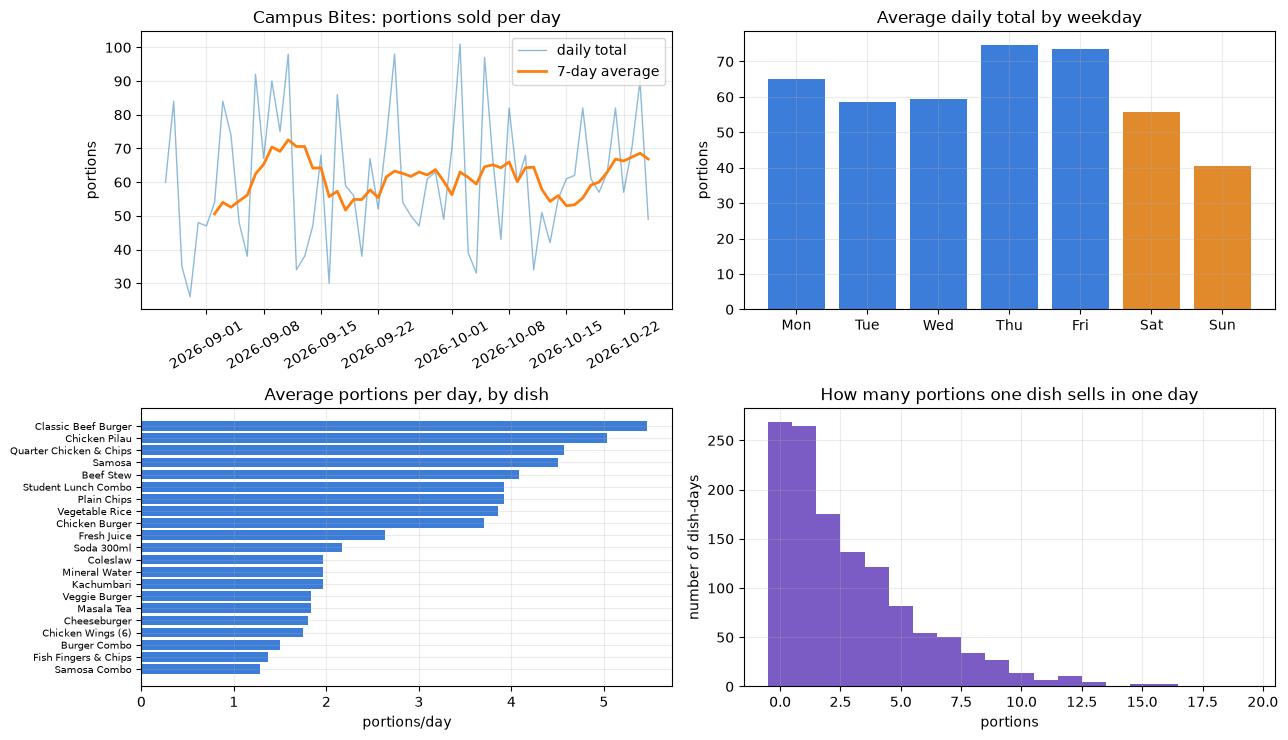

OBSERVATION 1 (weekly rhythm): the restaurant sells 67 portions on an average weekday but 48 at weekends (-28%). -> the day of the week is a useful clue.
OBSERVATION 2 (dish popularity): Classic Beef Burger is the best seller (5.5/day), Samosa Combo the slowest (1.3/day). -> the model must know WHICH dish it is forecasting.
OBSERVATION 3 (small, noisy numbers): one dish sells on average only 2.9 portions a day and 21% of dish-days are zero. Variance/mean = 3.1 (1.0 would be pure random 'Poisson' noise). -> single days are hard to predict exactly; an error of about 2 portions is expected.
OBSERVATION 4 (busy days are busy for everyone): the daily total swings from 26 to 101 portions. Correlation between a dish's sales and the restaurant's total that day: 0.30. -> yesterday's restaurant total is a useful 'how busy are we' clue.
OBSERVATION 5 (short history): only 60 days are available (no full year), so month or holiday effects cannot be learnt. -> month is deliberately NOT used.


In [4]:
fig, ax = plt.subplots(2, 2, figsize=(13, 7.5))
ax[0, 0].plot(TOTAL.index, TOTAL.values, lw=1, alpha=.5, label="daily total")
ax[0, 0].plot(TOTAL.index, TOTAL.rolling(7).mean(), lw=2, label="7-day average")
ax[0, 0].set(title="Campus Bites: portions sold per day", ylabel="portions"); ax[0, 0].legend(); ax[0, 0].tick_params(axis="x", rotation=30)

wd = TOTAL.groupby(TOTAL.index.dayofweek).mean()
ax[0, 1].bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], wd.values, color=["#3b7dd8"] * 5 + ["#e08a2c"] * 2)
ax[0, 1].set(title="Average daily total by weekday", ylabel="portions")

dish_mean = Q.mean().sort_values()
ax[1, 0].barh([NAMES[d] for d in dish_mean.index], dish_mean.values, color="#3b7dd8")
ax[1, 0].set(title="Average portions per day, by dish", xlabel="portions/day"); ax[1, 0].tick_params(axis="y", labelsize=7)

vals = Q.values.ravel()
ax[1, 1].hist(vals, bins=np.arange(vals.max() + 2) - .5, color="#7a5cc4")
ax[1, 1].set(title="How many portions one dish sells in one day", xlabel="portions", ylabel="number of dish-days")
plt.tight_layout(); plt.savefig(OUT / "01_eda.png", dpi=130); plt.show()

weekday_avg, weekend_avg = TOTAL[TOTAL.index.dayofweek < 5].mean(), TOTAL[TOTAL.index.dayofweek >= 5].mean()
print(f"OBSERVATION 1 (weekly rhythm): the restaurant sells {weekday_avg:.0f} portions on an average weekday but {weekend_avg:.0f} at weekends "
      f"({100*(weekend_avg/weekday_avg-1):+.0f}%). -> the day of the week is a useful clue.")
print(f"OBSERVATION 2 (dish popularity): {NAMES[dish_mean.index[-1]]} is the best seller ({dish_mean.iloc[-1]:.1f}/day), "
      f"{NAMES[dish_mean.index[0]]} the slowest ({dish_mean.iloc[0]:.1f}/day). -> the model must know WHICH dish it is forecasting.")
print(f"OBSERVATION 3 (small, noisy numbers): one dish sells on average only {vals.mean():.1f} portions a day and {100*(vals == 0).mean():.0f}% of dish-days are zero. "
      f"Variance/mean = {vals.var()/vals.mean():.1f} (1.0 would be pure random 'Poisson' noise). -> single days are hard to predict exactly; an error of about 2 portions is expected.")
print(f"OBSERVATION 4 (busy days are busy for everyone): the daily total swings from {TOTAL.min()} to {TOTAL.max()} portions. "
      f"Correlation between a dish's sales and the restaurant's total that day: {np.corrcoef(Q.values.ravel(), np.repeat(TOTAL.values, Q.shape[1]))[0,1]:.2f}. "
      f"-> yesterday's restaurant total is a useful 'how busy are we' clue.")
print(f"OBSERVATION 5 (short history): only {len(Q)} days are available (no full year), so month or holiday effects cannot be learnt. -> month is deliberately NOT used.")

## 3. Data preparation: features (the clues the model sees)

To forecast day *t* the model may **only use information known before day *t***. Using anything from day *t* itself is called **data leakage**: the model would look excellent in testing and then fail in the app.

| Feature | Plain meaning | Why it helps |
|---|---|---|
| `dish` (one-hot) | which of the 21 dishes | each dish has its own normal level (Observation 2) |
| `lag_1` | the dish's sales yesterday | recent momentum |
| `lag_7` | the dish's sales on the same weekday last week | weekly rhythm |
| `rolling_mean_7` | the dish's average over the previous 7 days | its recent normal level |
| `restaurant_total_lag_1` | all portions sold by the restaurant yesterday | how busy the restaurant is (Observation 4) |
| `day_of_week`, `is_weekend` | calendar of the forecast day (known in advance) | weekday vs weekend (Observation 1) |

**One-hot encoding** turns the dish name into 21 yes/no columns (1 for the dish, 0 for the others), because a model can only work with numbers and the dishes have no natural order.

The **same function** `make_features` is used for training, for evaluation and for live predictions, so the app can never feed the model numbers calculated a different way.

In [5]:
NUMERIC = ["lag_1", "lag_7", "rolling_mean_7", "restaurant_total_lag_1", "day_of_week", "is_weekend"]
COLUMNS = [f"dish={d}" for d in DISHES] + NUMERIC          # the 27 model inputs, in a fixed order

def make_features(dish_history, total_history, forecast_date):
    # dish_history / total_history: daily portions, oldest first, LAST value = the day BEFORE forecast_date
    if len(dish_history) < 7:
        raise ValueError(f"{len(dish_history)} days of history; at least 7 are needed")
    last7 = dish_history[-7:]
    return {"lag_1": float(dish_history[-1]), "lag_7": float(dish_history[-7]), "rolling_mean_7": sum(last7) / 7,
            "restaurant_total_lag_1": float(total_history[-1]),
            "day_of_week": forecast_date.weekday(), "is_weekend": int(forecast_date.weekday() >= 5)}

def to_vector(dish, feats):
    return [1.0 if d == dish else 0.0 for d in DISHES] + [float(feats[c]) for c in NUMERIC]

def features_for(i, dish, sales=Q):
    # features for forecasting day index i of the sales matrix, using only days 0 .. i-1
    total = sales.sum(axis=1)
    return make_features(sales[dish].iloc[:i].tolist(), total.iloc[:i].tolist(), sales.index[i].date())

def build_set(day_indexes, sales=Q):
    X, y, keys = [], [], []
    for i in day_indexes:
        for d in DISHES:
            X.append(to_vector(d, features_for(i, d, sales))); y.append(float(sales[d].iloc[i])); keys.append((sales.index[i], d))
    return np.asarray(X, dtype=np.float32), np.asarray(y), keys

**Leakage test.** We make a copy of the data, change every sale *after* day 40 to a silly value (999), and rebuild the features of day 40. If the features are the same, they cannot be using the future. We also check `make_features` against the usual pandas definitions (`shift` / `rolling`).

In [6]:
t = 40
tampered = Q.copy(); tampered.iloc[t:] = 999
for d in DISHES:
    assert features_for(t, d) == features_for(t, d, tampered), "LEAK: a feature changed when the future changed"

s = Q["samosa"]
pandas_version = {"lag_1": s.shift(1).iloc[t], "lag_7": s.shift(7).iloc[t], "rolling_mean_7": s.shift(1).rolling(7).mean().iloc[t]}
mine = features_for(t, "samosa")
assert all(np.isclose(mine[k], v) for k, v in pandas_version.items())
print("Leakage test PASSED: features for a day use only the days before it, and match the pandas definitions.")

FIRST = 7                                                   # the first 7 days only provide history
X_all, y_all, keys_all = build_set(range(FIRST, len(Q)))
print(f"Model-ready table: {len(y_all):,} rows ({len(Q)-FIRST} target days x {len(DISHES)} dishes), {X_all.shape[1]} input columns")
display(pd.DataFrame(X_all[:5, -6:], columns=NUMERIC).assign(dish=[k[1] for k in keys_all[:5]], target_portions=y_all[:5]))

Leakage test PASSED: features for a day use only the days before it, and match the pandas definitions.


Model-ready table: 1,113 rows (53 target days x 21 dishes), 27 input columns


,lag_1,lag_7,rolling_mean_7,restaurant_total_lag_1,day_of_week,is_weekend,dish,target_portions
0,1.0,1.0,2.285714,54.0,3.0,0.0,beef-stew,2.0
1,2.0,4.0,1.428571,54.0,3.0,0.0,burger-combo,1.0
2,5.0,4.0,3.857143,54.0,3.0,0.0,cheeseburger,4.0
3,4.0,3.0,2.142857,54.0,3.0,0.0,chicken-burger,9.0
4,0.0,4.0,2.285714,54.0,3.0,0.0,chicken-pilau,8.0


## 4. Modelling: the Random Forest

### 4.1 The theory in plain words
* A **decision tree** predicts by asking a chain of yes/no questions about the clues, e.g. *"Was the 7-day average above 3.5? Is it a weekend?"*, and ends at a **leaf** that holds the average sales of similar past days.
* One tree is unstable: it can **memorise** its training data (overfitting) and change a lot with small changes in the data.
* A **Random Forest** grows many trees. Each tree learns from a different random sample of the rows (**bootstrap sampling**) and considers a random choice of clues at each question. The forest's forecast is the **average of all trees**. Averaging many slightly different opinions cancels much of the noise.

**Why we kept Random Forest (lessons from the base model, `RandomForest_Base.ipynb`):** on 2 years of simulated data we tuned and compared five approaches with time-respecting cross-validation:

| Model (base notebook) | Test MAE (portions) |
|---|---|
| Gradient Boosting | 5.66 |
| Ridge Regression | 5.71 |
| **Random Forest** | **5.74** |
| Decision Tree | 5.95 |
| 7-day average (simple rule) | 6.22 |
| Same as yesterday (simple rule) | 8.16 |

The top three were within 0.1 portions of each other, less than the normal variation between folds (±0.46). We therefore chose on other grounds: a Random Forest needs no feature scaling, captures non-linear effects (e.g. "weekend AND this dish"), is hard to overfit badly, and **each prediction can be explained** (§8), which matters for a vendor trusting the number.

### 4.2 Settings (hyperparameters)
These values were **fixed before seeing any score**, in the project's written evaluation protocol (P-CB-1). With only 60 days of data, tuning would risk choosing settings that fit the test days by luck.

| Setting | Value | Meaning |
|---|---|---|
| `n_estimators` | 120 | number of trees averaged |
| `max_depth` | 8 | at most 8 questions per tree (a brake against memorising) |
| `min_samples_leaf` | 5 | every leaf must hold at least 5 past examples (another brake) |
| `bootstrap` | True | each tree sees a random resample of the rows |
| `random_state` | 2026 | repeatable randomness |

In [7]:
HYPERPARAMETERS = dict(n_estimators=120, max_depth=8, min_samples_leaf=5, bootstrap=True, random_state=SEED)

def new_forest():
    return RandomForestRegressor(**HYPERPARAMETERS, n_jobs=1)   # n_jobs=1 makes the result bit-for-bit repeatable

## 5. Evaluation: is the forest better than simple rules?

### 5.1 The four simple ("traditional") methods the forest must beat
| Method | Rule |
|---|---|
| Seven-day average | average of the dish's last 7 days |
| Same as yesterday | the dish's sales yesterday |
| Same-weekday average | average of the dish's last 4 same weekdays |
| Restaurant total × dish share | the restaurant's average day × this dish's share of the last 14 days |

### 5.2 Rolling-origin evaluation (a fair, time-respecting test)
We pretend to be on 23 Sep 2026: train on everything before, forecast the next 7 days, score, then move forward a week and **retrain** with the extra history. Five blocks cover **32 forecast days × 21 dishes = 672 forecasts**. Every forecast is made by a model that has **never seen that day**. A random shuffle split would let the model peek at the future, which is why it is not used for time series.

**Decision rule (written before scoring):** the forest is "better" only if its overall MAE is lower than the best simple method **and** it wins on at least 20 of the 32 days.

In [8]:
def seven_day_average(h, tot):   return sum(h[-7:]) / 7
def yesterday(h, tot):           return float(h[-1])
def same_weekday_average(h, tot):
    same = [h[-7 * k] for k in range(1, 5) if len(h) >= 7 * k]
    return sum(same) / len(same)
def total_and_share(h, tot):
    den = sum(tot[-14:]); return (sum(tot[-7:]) / 7) * (sum(h[-14:]) / den if den else 0.0)

TRADITIONAL = {"Seven-day average": seven_day_average, "Same as yesterday": yesterday,
               "Same-weekday average": same_weekday_average, "Total x share": total_and_share}
AI = "Random Forest"

first_fc, last_fc = Q.index.get_loc(pd.Timestamp("2026-09-24")), Q.index.get_loc(pd.Timestamp("2026-10-25"))
blocks = [list(range(i, min(i + 7, last_fc + 1))) for i in range(first_fc, last_fc + 1, 7)]

rows, block_models = [], []
for b, block in enumerate(blocks, 1):
    Xtr, ytr, _ = build_set(range(FIRST, block[0]))              # everything BEFORE the block
    forest = new_forest().fit(Xtr, ytr)
    Xb, yb, kb = build_set(block)
    ai = np.maximum(0, forest.predict(Xb))                       # portions cannot be negative
    block_models.append((forest, Xb, yb))
    for (day, dish), x_actual, p in zip(kb, yb, ai):
        i = Q.index.get_loc(day); h, tot = Q[dish].iloc[:i].tolist(), TOTAL.iloc[:i].tolist()
        rows.append({"date": day, "dish": dish, "block": b, "actual": x_actual, AI: p,
                     **{m: max(0.0, f(h, tot)) for m, f in TRADITIONAL.items()}})
    print(f"Block {b}: trained on {len(ytr):,} rows (to {Q.index[block[0]-1].date()}), forecast {Q.index[block[0]].date()} -> {Q.index[block[-1]].date()}")
cells = pd.DataFrame(rows)
METHODS = list(TRADITIONAL) + [AI]
print(f"\nScored forecasts: {len(cells)} ({cells.date.nunique()} days x {cells.dish.nunique()} dishes)")

Block 1: trained on 441 rows (to 2026-09-23), forecast 2026-09-24 -> 2026-09-30


Block 2: trained on 588 rows (to 2026-09-30), forecast 2026-10-01 -> 2026-10-07


Block 3: trained on 735 rows (to 2026-10-07), forecast 2026-10-08 -> 2026-10-14


Block 4: trained on 882 rows (to 2026-10-14), forecast 2026-10-15 -> 2026-10-21


Block 5: trained on 1,029 rows (to 2026-10-21), forecast 2026-10-22 -> 2026-10-25

Scored forecasts: 672 (32 days x 21 dishes)


### 5.3 Results
* **MAE**: average error in portions (main measure).
* **Bias**: average of (forecast − actual). Negative = tends to under-forecast.
* **WAPE**: total error as a % of total sales.
* **Short / left-over portions**: portions the vendor would have been short of, or had left over, over the 32 days.

In [9]:
def score(actual, fc):
    err = fc - actual
    return {"MAE": np.abs(err).mean(), "bias": err.mean(), "WAPE_%": 100 * np.abs(err).sum() / actual.sum(),
            "short_portions": np.maximum(actual - fc, 0).sum(), "left_over_portions": np.maximum(fc - actual, 0).sum()}

overall = pd.DataFrame({m: score(cells["actual"].values, cells[m].values) for m in METHODS}).T.sort_values("MAE")
display(overall.round(3))

daily_mae = cells.groupby("date").apply(lambda g: pd.Series({m: np.abs(g[m] - g["actual"]).mean() for m in METHODS}))
best_simple = overall.drop(index=AI)["MAE"].idxmin()
wins = {m: int((daily_mae[AI] < daily_mae[m] - 1e-9).sum()) for m in TRADITIONAL}
passed = overall.loc[AI, "MAE"] < overall.loc[best_simple, "MAE"] and wins[best_simple] >= 20
print(f"Best simple method: {best_simple} (MAE {overall.loc[best_simple, 'MAE']:.3f}) | Random Forest MAE {overall.loc[AI, 'MAE']:.3f}")
print("Days (of 32) on which the forest had the lower error:", wins)
print("DECISION:", "the forest met the rule." if passed else "the forest did NOT meet the rule: no advantage shown on this data.")

# Uncertainty: paired bootstrap of the daily MAE difference (forest minus method). Negative = forest better.
rng = np.random.default_rng(SEED); res = rng.integers(0, len(daily_mae), size=(2000, len(daily_mae)))
ci = {m: (lambda d: (d.mean(), *np.percentile(d.values[res].mean(axis=1), [2.5, 97.5])))(daily_mae[AI] - daily_mae[m]) for m in TRADITIONAL}
display(pd.DataFrame(ci, index=["mean difference", "95% low", "95% high"]).T.round(3))

# Same numbers as the app's stored evaluation? (the app's run with scikit-learn 1.9.1)
APP_MAE = {"Random Forest": 2.1609, "Seven-day average": 2.0493, "Total x share": 2.0779, "Same-weekday average": 2.2507, "Same as yesterday": 2.4405}
same = all(abs(overall.loc[m, "MAE"] - v) < 5e-4 for m, v in APP_MAE.items())
print("Matches the evaluation stored in the MloHub app:", same, "" if same else "(a different scikit-learn version can change the forest slightly)")

,MAE,bias,WAPE_%,short_portions,left_over_portions
Seven-day average,2.049,-0.044,68.926,703.429,673.714
Total x share,2.078,-0.044,69.886,713.020,683.306
Random Forest,2.161,0.061,72.679,705.508,746.613
Same-weekday average,2.251,-0.074,75.701,781.000,731.500
Same as yesterday,2.440,0.036,82.082,808.000,832.000


Best simple method: Seven-day average (MAE 2.049) | Random Forest MAE 2.161
Days (of 32) on which the forest had the lower error: {'Seven-day average': 13, 'Same as yesterday': 23, 'Same-weekday average': 17, 'Total x share': 11}
DECISION: the forest did NOT meet the rule: no advantage shown on this data.


,mean difference,95% low,95% high
Seven-day average,0.112,-0.004,0.227
Same as yesterday,-0.280,-0.547,-0.006
Same-weekday average,-0.090,-0.234,0.036
Total x share,0.083,-0.004,0.166


Matches the evaluation stored in the MloHub app: True 


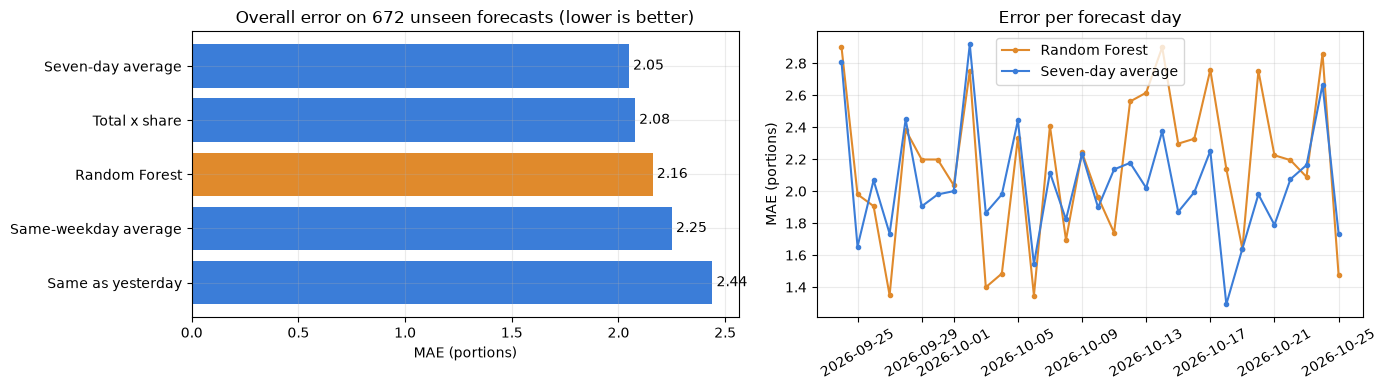

The forest had the lower error on 6 of 21 dishes.


,Random Forest,Seven-day average,forest_better
dish,,,
Burger Combo,1.31,1.26,False
Samosa Combo,1.36,1.22,False
Soda 300ml,1.48,1.29,False
Fish Fingers & Chips,1.57,1.42,False
Masala Tea,1.64,1.65,True
Chicken Wings (6),1.66,1.54,False
Veggie Burger,1.66,1.51,False
Coleslaw,1.74,1.79,True


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
o = overall["MAE"]
ax[0].barh(o.index[::-1], o.values[::-1], color=["#e08a2c" if m == AI else "#3b7dd8" for m in o.index[::-1]])
for i, v in enumerate(o.values[::-1]): ax[0].text(v, i, f" {v:.2f}", va="center")
ax[0].set(title="Overall error on 672 unseen forecasts (lower is better)", xlabel="MAE (portions)")
ax[1].plot(daily_mae.index, daily_mae[AI], marker="o", ms=3, label=AI, color="#e08a2c")
ax[1].plot(daily_mae.index, daily_mae[best_simple], marker="o", ms=3, label=best_simple, color="#3b7dd8")
ax[1].set(title="Error per forecast day", ylabel="MAE (portions)"); ax[1].legend(); ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(OUT / "02_evaluation.png", dpi=130); plt.show()

per_dish = cells.groupby("dish").apply(lambda g: pd.Series({AI: np.abs(g[AI] - g.actual).mean(), best_simple: np.abs(g[best_simple] - g.actual).mean()}))
per_dish["forest_better"] = per_dish[AI] < per_dish[best_simple]
print(f"The forest had the lower error on {per_dish.forest_better.sum()} of {len(per_dish)} dishes.")
display(per_dish.rename(index=NAMES).sort_values(AI).round(2).head(8))

**Interpretation.** On this short, noisy demonstration history the forest is **close to, but not better than,** the best simple rules: about 0.1 portions per dish-day worse than the seven-day average, a gap inside the 95% uncertainty range. It clearly beats "same as yesterday". With only 60 days and an average of about 3 portions per dish-day, most of the day-to-day variation is random and no method can predict it. In the base notebook, with 2 years of data, the forest beat the seven-day average by about 8%. More real history is what should let it pull ahead.

**What this means for the app:** the app shows the forest's forecast **next to** the seven-day average and says which method produced each figure. When the AI cannot answer (dish not covered, too little history, a day outside the tested range) it falls back to the seven-day average and **says why**. We report the result as it is rather than tuning until the forest wins.

## 6. The final model (what the app loads)

After evaluation we train once more on **all 1,113 rows** (target days 3 Sep – 25 Oct). This is the forest the app uses for live forecasts. We also measure which clues matter most, using **permutation importance**: scramble one clue across the 672 unseen evaluation forecasts and see how much worse the error gets. A big jump means the model relies on that clue. (The 21 dish columns are scrambled together as one clue, "which dish".)

Final forest: 120 trees, trained on 1,113 rows


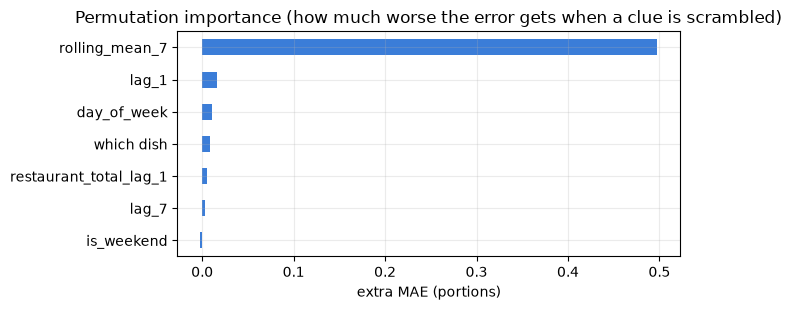

Most useful clues: rolling_mean_7, lag_1, day_of_week


In [11]:
engine = new_forest().fit(X_all, y_all)
print(f"Final forest: {len(engine.estimators_)} trees, trained on {len(y_all):,} rows")

GROUPS = {"which dish": list(range(len(DISHES)))} | {c: [len(DISHES) + j] for j, c in enumerate(NUMERIC)}
rng = np.random.default_rng(SEED); imp = {g: [] for g in GROUPS}
for forest, Xb, yb in block_models:
    base = np.abs(np.maximum(0, forest.predict(Xb)) - yb).mean()
    for g, cols in GROUPS.items():
        for _ in range(10):
            Xp = Xb.copy(); Xp[:, cols] = Xb[rng.permutation(len(Xb))][:, cols]
            imp[g].append(np.abs(np.maximum(0, forest.predict(Xp)) - yb).mean() - base)
importance = pd.Series({g: np.mean(v) for g, v in imp.items()}).sort_values()
ax = importance.plot(kind="barh", figsize=(7, 3.2), color="#3b7dd8")
ax.set(title="Permutation importance (how much worse the error gets when a clue is scrambled)", xlabel="extra MAE (portions)")
plt.tight_layout(); plt.savefig(OUT / "03_importance.png", dpi=130); plt.show()
print("Most useful clues:", ", ".join(importance.sort_values(ascending=False).index[:3]))

## 7. Deployment: the engine as the app uses it

In MloHub the vendor opens **AI Lab** (Android app or web), picks a **dish** and a **date**, and Django runs the model. Kotlin only displays what Django returns. Below is the same logic in plain Python, with the same input checks the app makes:

| Input problem | What the engine does |
|---|---|
| Date not in the form `2026-10-20` | refuses: "Choose a date in the form 2026-10-20" |
| Dish the model does not know | refuses (it never guesses) |
| Fewer than 7 days of sales before the date | refuses: features cannot be calculated honestly |
| A date more than one day after the last finished day | refuses: it would need sales that have not happened yet |
| A feature that is missing, not a number, negative, too large, or a weekend flag that contradicts the date | refuses (never repaired or filled in silently) |

Rule: **invalid input never produces a number**. It produces a clear message, and nothing is guessed.

In [12]:
class InvalidInput(ValueError):
    pass

MAX_PORTIONS = 1000

def check_features(row):
    # same rules as the app's CampusBitesForest.validate_row: refuse, never repair
    expected = ["dish"] + NUMERIC
    missing, extra = [k for k in expected if k not in row], [k for k in row if k not in expected]
    if missing or extra:
        raise InvalidInput(f"inputs must be exactly {expected}; missing {missing}, unexpected {extra}")
    if row["dish"] not in DISHES:
        raise InvalidInput(f"dish {row['dish']!r} is not covered by this model")
    clean = {"dish": row["dish"]}
    for name in NUMERIC:
        v = row[name]
        if isinstance(v, bool) or not isinstance(v, (int, float, np.integer, np.floating)) or not np.isfinite(v):
            raise InvalidInput(f"{name} must be a number, got {v!r}")
        clean[name] = float(v)
    if clean["day_of_week"] not in range(7):
        raise InvalidInput("day_of_week must be 0 (Monday) to 6 (Sunday)")
    if clean["is_weekend"] != float(clean["day_of_week"] >= 5):
        raise InvalidInput("is_weekend contradicts day_of_week")
    for name in ("lag_1", "lag_7", "rolling_mean_7", "restaurant_total_lag_1"):
        if not 0 <= clean[name] <= MAX_PORTIONS:
            raise InvalidInput(f"{name} must be between 0 and {MAX_PORTIONS} portions, got {clean[name]:g}")
    return clean

def predict_from_features(row, model=engine):
    clean = check_features(row)
    x = np.asarray([to_vector(clean["dish"], clean)], dtype=np.float32)
    return max(0.0, float(model.predict(x)[0])), x[0]

def forecast(dish, date_text, sales=Q, model=engine):
    # What the app does when the vendor picks a dish and a date
    try:
        day = dt.date.fromisoformat(str(date_text))
    except ValueError:
        raise InvalidInput("Choose a date in the form 2026-10-20.") from None
    if dish not in sales.columns:
        raise InvalidInput(f"Unknown dish {dish!r}: the model covers Campus Bites' {len(DISHES)} dishes only.")
    first, latest = sales.index[0].date(), sales.index[-1].date() + dt.timedelta(days=1)
    if day > latest:
        raise InvalidInput(f"Only the next trading day can be forecast ({latest} is the latest).")
    if day < first + dt.timedelta(days=7):
        raise InvalidInput(f"Fewer than 7 days of sales before that date (earliest supported day is {first + dt.timedelta(days=7)}).")
    i = int((day - first).days)                               # index of the forecast day (may be one past the data)
    hist, tot = sales[dish].iloc[:i].tolist(), sales.sum(axis=1).iloc[:i].tolist()
    feats = make_features(hist, tot, day)
    value, x = predict_from_features({"dish": dish, **feats}, model)
    out = {"dish": NAMES[dish], "date": str(day), "weekday": day.strftime("%A"), "forest_forecast": round(value, 1),
           "prepare_about": int(np.ceil(value)), "seven_day_average": round(seven_day_average(hist, tot), 1)}
    if i < len(sales):
        out["actual_sold"] = int(sales[dish].iloc[i])      # known only for past days (shown for checking)
    return out

### 7.1 Valid inputs: the forecast changes when the situation changes
The same dish on a weekday and at the weekend, different dishes on the same day, and the live forecast for the next day after the data (26 Oct 2026).

In [13]:
valid_requests = [("masala-tea", "2026-10-21"), ("masala-tea", "2026-10-25"), ("quarter-chicken-chips", "2026-10-21"),
                  ("quarter-chicken-chips", "2026-10-25"), ("beef-stew", "2026-10-21"), ("chicken-pilau", "2026-10-26")]
display(pd.DataFrame([forecast(d, day) for d, day in valid_requests]))

,dish,date,weekday,forest_forecast,prepare_about,seven_day_average,actual_sold
0,Masala Tea,2026-10-21,Wednesday,1.8,2,1.0,1.0
1,Masala Tea,2026-10-25,Sunday,0.9,1,1.3,1.0
2,Quarter Chicken & Chips,2026-10-21,Wednesday,4.5,5,3.4,1.0
3,Quarter Chicken & Chips,2026-10-25,Sunday,1.9,2,2.3,3.0
4,Beef Stew,2026-10-21,Wednesday,7.7,8,9.1,8.0
5,Chicken Pilau,2026-10-26,Monday,9.0,10,10.9,NaN


**What-if test.** We hold everything else fixed and change one input at a time. A sensible model should forecast **more** when recent sales are higher and **less** at the weekend, when this restaurant is quieter.

In [14]:
base_row = {"dish": "chicken-pilau", "lag_1": 3, "lag_7": 3, "rolling_mean_7": 3.0, "restaurant_total_lag_1": 60, "day_of_week": 2, "is_weekend": 0}
scenarios = {"baseline (Wednesday, normal week)": {},
             "recent sales doubled": {"lag_1": 6, "lag_7": 6, "rolling_mean_7": 6.0},
             "recent sales very low": {"lag_1": 0, "lag_7": 1, "rolling_mean_7": 1.0},
             "restaurant very busy yesterday": {"restaurant_total_lag_1": 95},
             "same history but a Sunday": {"day_of_week": 6, "is_weekend": 1}}
what_if = [{"scenario": s, **{k: v for k, v in {**base_row, **chg}.items() if k != "dish"},
            "forecast": round(predict_from_features({**base_row, **chg})[0], 2)} for s, chg in scenarios.items()]
display(pd.DataFrame(what_if))

,scenario,lag_1,lag_7,rolling_mean_7,restaurant_total_lag_1,day_of_week,is_weekend,forecast
0,"baseline (Wednesday, normal week)",3,3,3.0,60,2,0,3.53
1,recent sales doubled,6,6,6.0,60,2,0,7.65
2,recent sales very low,0,1,1.0,60,2,0,2.17
3,restaurant very busy yesterday,3,3,3.0,95,2,0,3.76
4,same history but a Sunday,3,3,3.0,60,6,1,2.55


### 7.2 Invalid inputs: refused with a clear message, never a made-up number

In [15]:
bad_requests = [
    ("forecast", ("pizza", "2026-10-21"),                 "dish not on the menu"),
    ("forecast", ("masala-tea", "21/10/2026"),            "wrong date format"),
    ("forecast", ("masala-tea", "tomorrow"),              "text instead of a date"),
    ("forecast", ("masala-tea", "2026-08-30"),            "too little history"),
    ("forecast", ("masala-tea", "2026-11-15"),            "too far in the future"),
    ("features", {**base_row, "lag_1": -4},               "negative sales"),
    ("features", {**base_row, "rolling_mean_7": float("nan")}, "missing value (NaN)"),
    ("features", {**base_row, "lag_7": "five"},           "text instead of a number"),
    ("features", {**base_row, "day_of_week": 6},          "weekend flag contradicts the day"),
    ("features", {k: v for k, v in base_row.items() if k != "lag_7"}, "a feature left out"),
    ("features", {**base_row, "restaurant_total_lag_1": 50000}, "impossible value"),
]
results = []
for kind, args, label in bad_requests:
    try:
        out = forecast(*args) if kind == "forecast" else predict_from_features(args)[0]
        results.append({"test": label, "result": f"ACCEPTED: {out}"})
    except InvalidInput as e:
        results.append({"test": label, "result": f"REFUSED: {e}"})
pd.set_option("display.max_colwidth", 120)
display(pd.DataFrame(results))
assert all(r["result"].startswith("REFUSED") for r in results), "an invalid input was accepted"
print("All", len(results), "invalid inputs were refused.")

,test,result
0,dish not on the menu,REFUSED: Unknown dish 'pizza': the model covers Campus Bites' 21 dishes only.
1,wrong date format,REFUSED: Choose a date in the form 2026-10-20.
2,text instead of a date,REFUSED: Choose a date in the form 2026-10-20.
3,too little history,REFUSED: Fewer than 7 days of sales before that date (earliest supported day is 2026-09-03).
4,too far in the future,REFUSED: Only the next trading day can be forecast (2026-10-26 is the latest).
5,negative sales,"REFUSED: lag_1 must be between 0 and 1000 portions, got -4"
6,missing value (NaN),"REFUSED: rolling_mean_7 must be a number, got nan"
7,text instead of a number,"REFUSED: lag_7 must be a number, got 'five'"
8,weekend flag contradicts the day,REFUSED: is_weekend contradicts day_of_week
9,a feature left out,"REFUSED: inputs must be exactly ['dish', 'lag_1', 'lag_7', 'rolling_mean_7', 'restaurant_total_lag_1', 'day_of_week'..."


All 11 invalid inputs were refused.


## 8. Explainable AI: why did the model give this number?

A vendor should not have to trust a "black box". For any single forecast we split the number into **contributions**, one per clue:

* Every tree starts at the **average** of its training data (the *starting point*).
* Each yes/no question moves the estimate up or down on the way to the leaf. We credit that move to the clue the question used.
* Averaging over the 120 trees gives: **forecast = starting point + Σ contributions** (exactly, no approximation).

This method is called *tree-path decomposition* (also known as the *Saabas* method). We also report the **spread of the 120 trees**: when they disagree a lot, the forecast is less certain.

Quarter Chicken & Chips on Wednesday 2026-10-21: forecast 4.5 portions  ->  prepare about 5
  Starting point (average dish-day in training): 2.99
  +0.95  sales yesterday (value 9)
  +0.55  average of the last 7 days (value 3.42857)
  -0.28  how busy the restaurant was yesterday (value 63)
  +0.21  day of the week (value 2)
  +0.08  sales on the same weekday last week (value 1)
  -0.05  which dish it is
  +0.04  weekend or weekday (value 0)
  Certainty: 80% of the trees said between 1.9 and 7.3 portions.
  (Actually sold that day: 1)


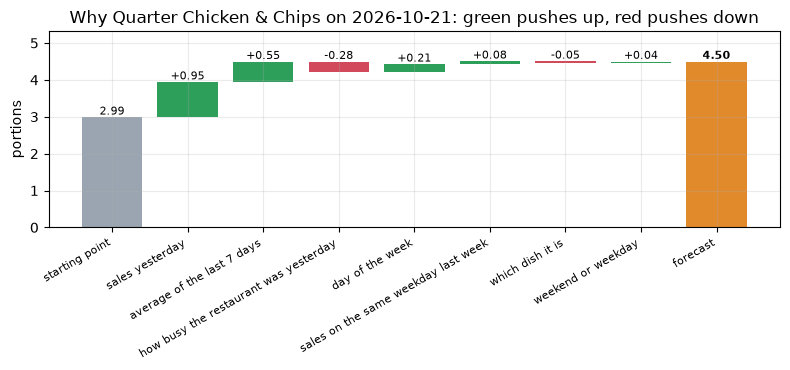


Quarter Chicken & Chips on Sunday 2026-10-25: forecast 1.9 portions  ->  prepare about 2
  Starting point (average dish-day in training): 2.99
  -0.54  average of the last 7 days (value 2.28571)
  -0.43  day of the week (value 6)
  -0.20  weekend or weekday (value 1)
  +0.16  sales on the same weekday last week (value 3)
  -0.09  sales yesterday (value 0)
  +0.04  which dish it is
  +0.01  how busy the restaurant was yesterday (value 90)
  Certainty: 80% of the trees said between 0.8 and 3.6 portions.
  (Actually sold that day: 3)


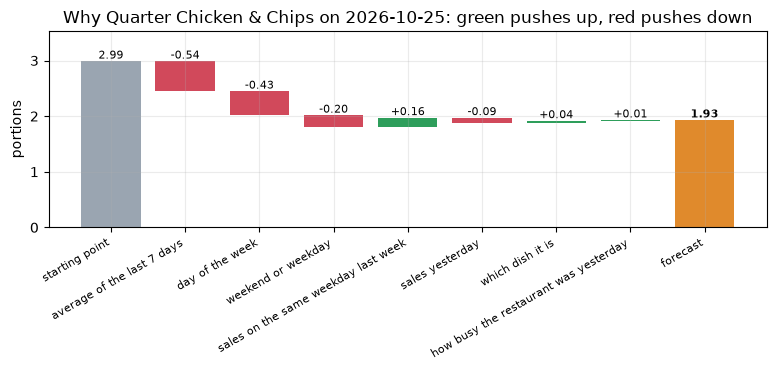

In [16]:
PLAIN = {"which dish": "which dish it is", "lag_1": "sales yesterday", "lag_7": "sales on the same weekday last week",
         "rolling_mean_7": "average of the last 7 days", "restaurant_total_lag_1": "how busy the restaurant was yesterday",
         "day_of_week": "day of the week", "is_weekend": "weekend or weekday"}

def explain(x, model=engine):
    start, contrib, tree_preds = 0.0, np.zeros(len(x)), []
    for est in model.estimators_:
        t, node = est.tree_, 0
        v = t.value[:, 0, 0]
        start += v[0]
        while t.children_left[node] != -1:
            nxt = t.children_left[node] if x[t.feature[node]] <= t.threshold[node] else t.children_right[node]
            contrib[t.feature[node]] += v[nxt] - v[node]
            node = nxt
        tree_preds.append(v[node])
    n = len(model.estimators_)
    grouped = {g: contrib[cols].sum() / n for g, cols in GROUPS.items()}
    return start / n, grouped, np.asarray(tree_preds)

def explain_forecast(dish, date_text):
    f = forecast(dish, date_text)
    day = dt.date.fromisoformat(date_text); i = (day - Q.index[0].date()).days
    feats = make_features(Q[dish].iloc[:i].tolist(), TOTAL.iloc[:i].tolist(), day)
    x = np.asarray(to_vector(dish, feats), dtype=np.float32)
    start, parts, trees = explain(x)
    assert np.isclose(start + sum(parts.values()), engine.predict(x[None])[0])     # the parts add up exactly
    lo, hi = np.percentile(trees, [10, 90])
    print(f"{f['dish']} on {f['weekday']} {f['date']}: forecast {f['forest_forecast']} portions  ->  prepare about {f['prepare_about']}")
    print(f"  Starting point (average dish-day in training): {start:.2f}")
    for g, v in sorted(parts.items(), key=lambda kv: -abs(kv[1])):
        shown = "" if g == "which dish" else f" (value {feats[g]:g})"
        print(f"  {'+' if v >= 0 else '-'}{abs(v):.2f}  {PLAIN[g]}{shown}")
    print(f"  Certainty: 80% of the trees said between {lo:.1f} and {hi:.1f} portions.")
    if "actual_sold" in f: print(f"  (Actually sold that day: {f['actual_sold']})")
    return start, parts, f

def waterfall(start, parts, title):
    items = sorted(parts.items(), key=lambda kv: -abs(kv[1]))
    fig, ax = plt.subplots(figsize=(8, 3.8)); level, peak = start, start
    ax.bar(0, start, color="#9aa5b1"); ax.text(0, start, f"{start:.2f}", ha="center", va="bottom", fontsize=8); labels = ["starting point"]
    for k, (g, v) in enumerate(items, 1):
        ax.bar(k, v, bottom=level, color="#2e9e5b" if v >= 0 else "#d1495b")
        ax.text(k, max(level, level + v), f"{v:+.2f}", ha="center", va="bottom", fontsize=8)
        level += v; peak = max(peak, level); labels.append(PLAIN[g])
    ax.bar(len(items) + 1, level, color="#e08a2c"); ax.text(len(items) + 1, level, f"{level:.2f}", ha="center", va="bottom", fontsize=8, weight="bold")
    labels.append("forecast"); ax.set_ylim(0, peak * 1.18)
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=30, ha="right", fontsize=8)
    ax.set(ylabel="portions", title=title); plt.tight_layout(); plt.show()

s, p, f = explain_forecast("quarter-chicken-chips", "2026-10-21")
waterfall(s, p, f"Why {f['dish']} on {f['date']}: green pushes up, red pushes down")
print()
s, p, f = explain_forecast("quarter-chicken-chips", "2026-10-25")
waterfall(s, p, f"Why {f['dish']} on {f['date']}: green pushes up, red pushes down")

## 9. Save the engine and prove it is the same model the app runs

We save the trained pipeline with `joblib`, plus a small **manifest** recording what the model is (features, settings, data fingerprint, scores). The app stores the same forest as plain NumPy arrays, which are safer to load than pickle files, and it keeps **508 reference predictions**. If this notebook's forest gives the same 508 numbers, then the notebook and the app hold the same engine.

*Security note:* only load `.joblib` files you made yourself. Opening one can run code.

In [17]:
joblib.dump(engine, OUT / "randomforest_final_rf_cb_v1.joblib", compress=3)
manifest = {"model_id": "rf_cb_v1", "approach": "Random Forest regression", "target": "portions of one dish sold on the next day",
            "inputs": COLUMNS, "hyperparameters": HYPERPARAMETERS, "training_rows": int(len(y_all)),
            "training_target_days": [str(keys_all[0][0].date()), str(keys_all[-1][0].date())],
            "data_sha256": sha, "evaluation_mae": overall["MAE"].round(4).to_dict(), "decision_rule_passed": bool(passed),
            "scikit_learn": sklearn.__version__, "data_note": "demonstration data, not real customers"}
(OUT / "model_manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")

ref = json.loads(get_file("app_reference_cases.json").read_text(encoding="utf-8"))
diffs = []
for case in ref["cases"]:
    r = case["input"]
    x = np.asarray([to_vector(r["dish_slug"], r)], dtype=np.float32)
    diffs.append(abs(engine.predict(x)[0] - case["expected_raw"]))
print(f"Compared with the app on {len(diffs)} reference cases: largest difference = {max(diffs):.2e} portions")
print("IDENTICAL to the model inside MloHub." if max(diffs) < 1e-9 else
      "Small differences: probably a different scikit-learn version from the app's 1.9.1.")

Compared with the app on 508 reference cases: largest difference = 0.00e+00 portions
IDENTICAL to the model inside MloHub.


## 10. Summary

| Stage | What we did |
|---|---|
| Business | Forecast tomorrow's portions per dish so small vendors waste less and run out less often |
| Data | 60 days × 21 dishes of Campus Bites sales (3,666 portions), fingerprint-checked; complete, no gaps |
| Preparation | 7 leak-free clues built by one shared function, proven by a leakage test |
| Modelling | Random Forest (120 trees, depth ≤ 8, leaves ≥ 5), chosen from the base-model comparison |
| Evaluation | Rolling-origin test on 672 unseen forecasts against 4 simple rules, with a decision rule fixed in advance |
| Deployment | Same checks as the app: valid inputs give forecasts that respond sensibly, invalid inputs are refused with a reason. Every forecast can be explained clue by clue. Matches the app's model exactly |

**Honest conclusion:** the engine works end to end, and its forecasts change sensibly with the inputs. On the 60-day demonstration history it is **as good as, but not better than**, a seven-day average (MAE ≈ 2.2 vs 2.0 portions). That is why the app always shows both, labels which method produced each figure, and falls back to the average with a reason when the AI cannot answer.

**Limitations and next steps:**
1. Demonstration data, not real customers. Retrain and re-evaluate once real vendors use MloHub.
2. 60 days of one restaurant. More history (and holidays, weather, promotions) should help the forest. On 2 years of data in the base notebook it beat the seven-day average by about 8%.
3. Sales are not the same as demand: a sold-out dish hides demand that was there.